See “Feature convergence quantification” in the Methods for the rationale and definition of normalized feature separation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

ROOT = Path.cwd()
if ROOT.name == 'figure_code':
    ROOT = ROOT.parent

DATA_DIR = ROOT / 'data'

data_dir = DATA_DIR

C_LINE = '#B8B8B8'
C_ACC = '#4C72B0'
C_SEP = '#C44E52'
C_ZERO = '#555555'

mpl.rcParams.update({
    'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.7, 'xtick.major.width': 0.7, 'ytick.major.width': 0.7,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

In [2]:
def _metrics(g):
    """Median ROI accuracy per endpoint feature and normalized sm-lv separation."""
    feat_acc = g.groupby('feature')['rank_acc'].median()
    acc0 = feat_acc - 0.5

    sm = acc0['sm']
    lv = acc0['lv']
    denom = (sm + lv) / 2

    return {
        'sm_rank_acc': sm + 0.5,
        'lv_rank_acc': lv + 0.5,
        'raw_gap': sm - lv,
        'norm_gap': (sm - lv) / denom if denom > 1e-6 else np.nan,
        'endpoint_signal': denom,
    }


def load_state_summary():
    d = pd.read_csv(data_dir / 'gaps.csv')
    rec = d[d.side.eq('recall') & d.variant.eq('fitted')]
    enc = d[d.side.eq('encoding') & d.direction.eq('avg')
            & d.variant.eq('blur') & d.sigma_tr.eq(0)]

    def prep(x):
        if x.empty or x['sub'].isna().any() or x['sub'].duplicated().any():
            raise ValueError('Missing data or invalid subject IDs.')
        return x.rename(columns={'median_sm': 'sm_rank_acc',
                                 'median_lv': 'lv_rank_acc'}).set_index('sub')

    rec, enc = prep(rec), prep(enc)
    subs = sorted(rec.index.intersection(enc.index))
    if not subs:
        raise ValueError('No matched subjects.')
    return rec.loc[subs], enc.loc[subs]

rec_s, enc_s = load_state_summary()

In [23]:
def panel_states(axes, rec, enc):
    ax = axes[0]

    e = enc['endpoint_signal'].values * 100 + 50
    r = rec['endpoint_signal'].values * 100 + 50

    for a, b in zip(e, r):
        ax.plot([0, 1], [a, b], color=C_LINE, lw=0.6, alpha=0.85, zorder=1)

    ax.scatter(np.zeros(len(e)), e, s=10, color=C_ACC, alpha=0.6, edgecolors='none', zorder=2)
    ax.scatter(np.ones(len(r)), r, s=10, color=C_ACC, alpha=0.6, edgecolors='none', zorder=2)

    for xi, vals in [(-0.18, e), (1.18, r)]:
        m = np.median(vals)
        lo, hi = np.percentile(vals, [25, 75])
        ax.errorbar(xi, m, yerr=[[m - lo], [hi - m]], color=C_ACC, marker='o', ms=4, lw=1.5, capsize=3, zorder=3)

    ax.axhline(50, color=C_ZERO, lw=0.7, ls='--', zorder=0)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Encoding', 'Recall'])
    ax.set_xlim(-0.45, 1.45)
    ax.set_ylabel('median rank accuracy (%)')
    


    ax = axes[1]

    e_sep = enc['norm_gap'].values
    r_sep = rec['norm_gap'].values
    delta = r_sep - e_sep
    x = np.linspace(-0.12, 0, len(delta))

    ax.scatter(x, delta, s=12, color=C_SEP, alpha=0.65, edgecolors='none', zorder=2)

    med = np.median(delta)
    lo, hi = np.percentile(delta, [25, 75])
    ax.errorbar(0.22, med, yerr=[[med - lo], [hi - med]], color=C_SEP, marker='o', ms=5, lw=1.6, capsize=3, zorder=3)

    ax.axhline(0, color=C_ZERO, lw=0.8, ls='--', zorder=0)
    ax.text(0.4, -0.22, 'uniform attenuation', transform=ax.get_yaxis_transform(), ha='left', va='bottom', fontsize=9, color=C_ZERO)

    ax.set_xlim(-0.25, 0.45)
    ax.set_xticks([])
    ax.set_ylim(-1.6, 1.6)
    ax.set_ylabel('change in feature separation\n(recall − encoding)')

    valid = np.isfinite(e_sep) & np.isfinite(r_sep)
    stat, p = wilcoxon(r_sep[valid], e_sep[valid], alternative='less')
    sep_retained = np.median(r_sep[valid] / e_sep[valid])

    print(
        f'n = {valid.sum()}; '
        f'median encoding separation = {np.median(e_sep[valid]):.3f}; '
        f'recall = {np.median(r_sep[valid]):.3f}; '
        f'median change = {np.median(delta[valid]):.3f}; '
        f'separation retained = {sep_retained:.2f}; '
        f'p = {p:.4g}'
    )

n = 16; median encoding separation = 0.788; recall = 0.200; median change = -0.552; separation retained = 0.26; p = 4.578e-05


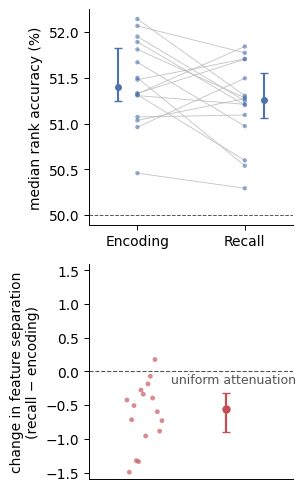

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(3, 5))
panel_states(axes, rec_s, enc_s)
fig.tight_layout(w_pad=1.8)